In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

df = pd.read_csv("../firsthalfdayproject/clean_data.csv")

os.makedirs("reports/figures", exist_ok=True)

print(df.head())

     id          name department   salary       city  age  experience_years  \
0  1001    Arun Kumar      Sales  84000.0    Chennai   43                20   
1  1002       Priya R         Hr  64500.0  Hyderabad   27                 4   
2  1003  Rahul Sharma         It  77500.0  Bangalore   35                13   
3  1004    Divya Iyer    Finance  89500.0       Pune   38                16   
4  1005   Karthik Rao  Marketing  77500.0     Mumbai   36                 7   

   performance_score  monthly_sales joining_date  gender contract_type  
0                2.5        68500.0   2020-07-03  Female     Permanent  
1                4.6        67500.0   2024-08-15    Male        Intern  
2                2.5        58500.0   2020-08-10    Male      Contract  
3                4.2        93000.0   2022-09-15  Female     Permanent  
4                4.4        66000.0   2019-10-16  Female        Intern  


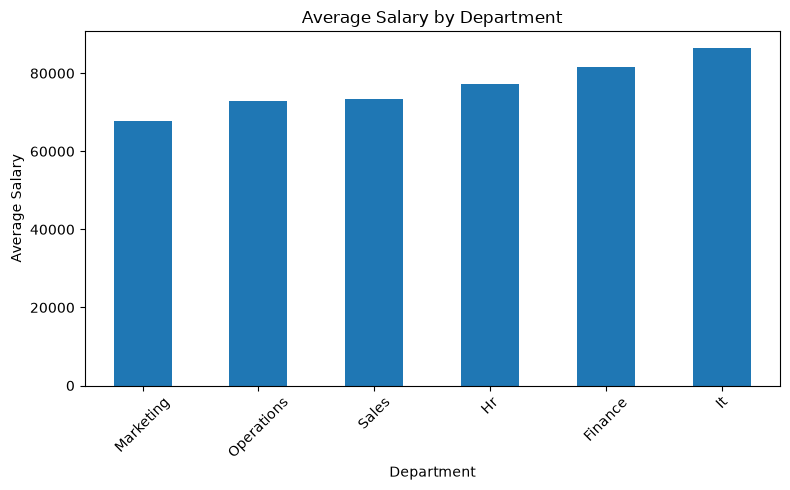

Insight: The chart compares average salaries across departments.


In [2]:
department_salary = df.groupby("department")["salary"].mean().sort_values()

plt.figure(figsize=(8, 5))
department_salary.plot(kind="bar")
plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("reports/figures/bar_chart.png")
plt.show()

print("Insight: The chart compares average salaries across departments.")

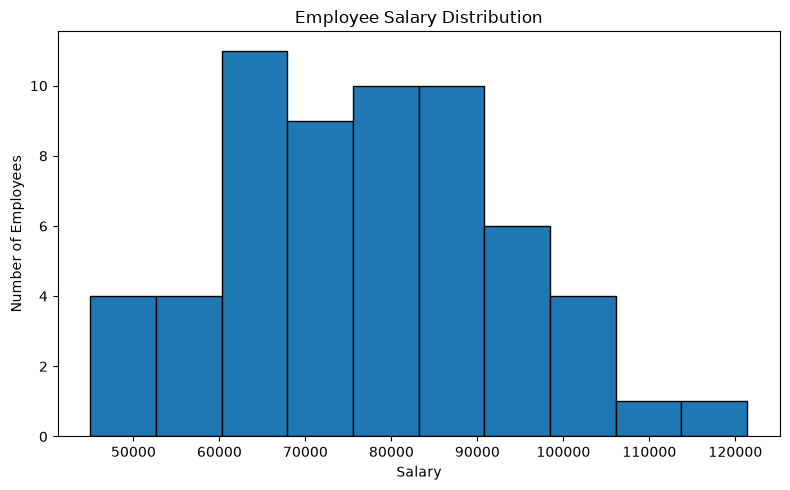

Insight: The histogram shows how employee salaries are distributed.


In [3]:
salary_values = df["salary"]

plt.figure(figsize=(8, 5))
plt.hist(salary_values, bins=10, edgecolor="black")
plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.savefig("reports/figures/histogram.png")
plt.show()

print("Insight: The histogram shows how employee salaries are distributed.")

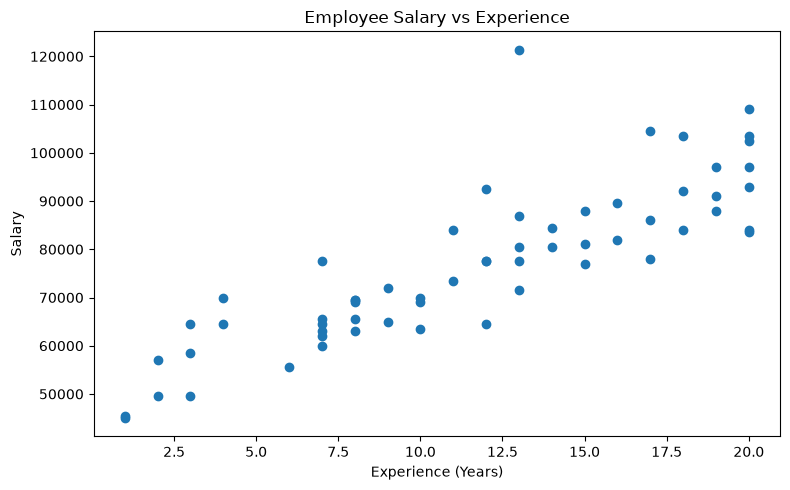

Insight: The scatter plot shows the relationship between employee experience and salary.


In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(df["experience_years"], df["salary"])
plt.title("Employee Salary vs Experience")
plt.xlabel("Experience (Years)")
plt.ylabel("Salary")
plt.tight_layout()
plt.savefig("reports/figures/scatter_plot.png")
plt.show()

print("Insight: The scatter plot shows the relationship between employee experience and salary.")

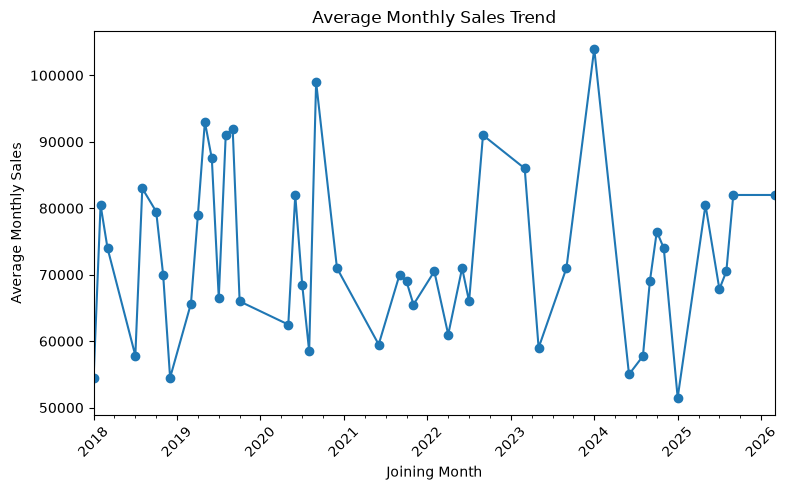

Insight: The line chart shows average monthly sales grouped by employee joining month.


In [5]:
df["joining_date"] = pd.to_datetime(df["joining_date"])

monthly_sales = df.groupby(
    df["joining_date"].dt.to_period("M")
)["monthly_sales"].mean()

plt.figure(figsize=(8, 5))
monthly_sales.plot(kind="line", marker="o")
plt.title("Average Monthly Sales Trend")
plt.xlabel("Joining Month")
plt.ylabel("Average Monthly Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("reports/figures/line_chart.png")
plt.show()

print("Insight: The line chart shows average monthly sales grouped by employee joining month.")

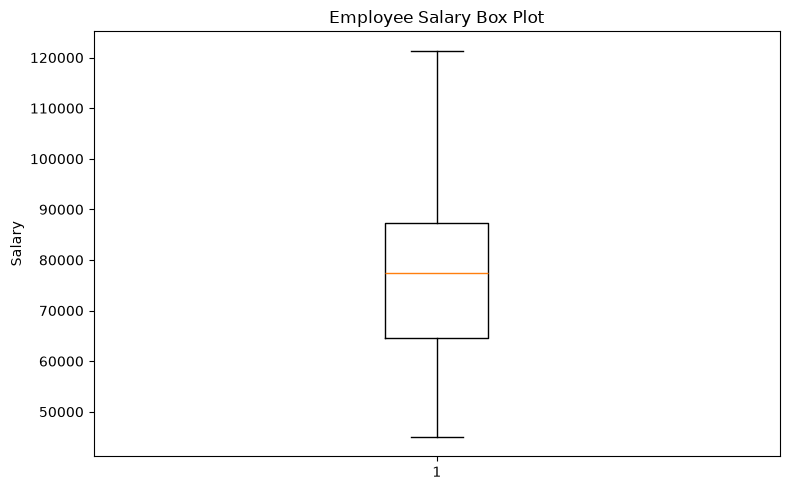

Insight: The box plot shows the spread of employee salaries and potential outliers.


In [6]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["salary"])
plt.title("Employee Salary Box Plot")
plt.ylabel("Salary")
plt.tight_layout()
plt.savefig("reports/figures/box_plot.png")
plt.show()

print("Insight: The box plot shows the spread of employee salaries and potential outliers.")

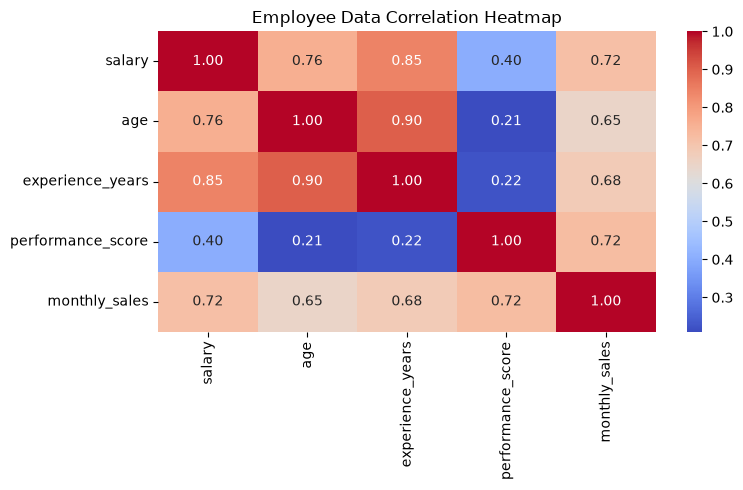

Insight: The heatmap shows the strength and direction of relationships between numerical variables.


In [8]:
import seaborn as sns

plt.figure(figsize=(8, 5))
correlation = df[["salary", "age", "experience_years", "performance_score", "monthly_sales"]].corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Employee Data Correlation Heatmap")
plt.tight_layout()
plt.savefig("reports/figures/heatmap.png")
plt.show()

print("Insight: The heatmap shows the strength and direction of relationships between numerical variables.")

In [9]:
print("All five required visualizations are completed.")

All five required visualizations are completed.


In [10]:
findings = """
Employee Data Analysis - Key Findings

Problem:
Analyze employee data to understand salary distribution, experience,
performance, and monthly sales.

Data:
The analysis uses the cleaned employee dataset.

Three Key Insights:
1. Average salaries differ across departments.
2. Salary generally has a positive relationship with employee experience.
3. Employee characteristics show different relationships with monthly sales.

Two Recommendations:
1. Review salary differences across departments for fairness.
2. Analyze employee experience and performance to identify opportunities
   to improve sales.

"""

with open("reports/findings_summary.txt", "w") as file:
    file.write(findings)

print("Findings summary saved.")

Findings summary saved.


In [14]:
!python -m jupyter nbconvert --to html employee_data_analysis.ipynb

[NbConvertApp] Converting notebook employee_data_analysis.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 523193 bytes to employee_data_analysis.html


In [15]:
%%writefile requirements.txt
pandas
matplotlib
seaborn
nbconvert

Writing requirements.txt


In [16]:
%%writefile README.md
# Employee Data Analysis Project

## Requirements
Install the required libraries:
pip install -r requirements.txt

## How to Run
1. Open employee_data_analysis.ipynb in VS Code.
2. Run the notebook cells from top to bottom.
3. The charts are saved in reports/figures/.
4. The findings summary is saved in reports/findings_summary.txt.
5. Open employee_data_analysis.html to view the exported report.

Writing README.md


In [17]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d != ".git" and d != "__pycache__"]
    for file in files:
        print(os.path.join(root, file))

.\employee_data_analysis.html
.\employee_data_analysis.ipynb
.\employee_project_dataset_fixed.csv
.\README.md
.\requirements.txt
.\reports\findings_summary.txt
.\reports\figures\bar_chart.png
.\reports\figures\box_plot.png
.\reports\figures\heatmap.png
.\reports\figures\histogram.png
.\reports\figures\line_chart.png
.\reports\figures\scatter_plot.png
